In [1]:

# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")


All libraries imported successfully!


In [2]:

# Step 2: Load the dataset

df = pd.read_csv("titanic.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [3]:

# Count missing values in each column
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values[missing_values > 0])

# Calculate the percentage of missing values
missing_percentage = (df.isnull().sum() / len(df)) * 100

print("\nMissing value percentages:")
print(missing_percentage[missing_percentage > 0].round(2))


Missing values in each column:
Age         177
Cabin       687
Embarked      2
dtype: int64

Missing value percentages:
Age         19.87
Cabin       77.10
Embarked     0.22
dtype: float64


Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.62
1    38.38
Name: proportion, dtype: float64


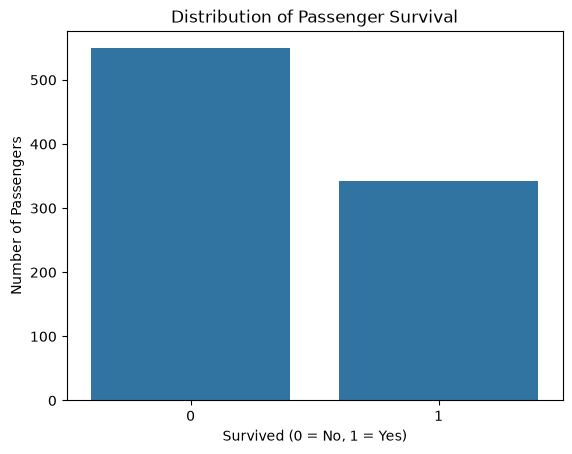

In [4]:

# Count passengers in each survival category
print(df["Survived"].value_counts())

# Calculate percentages
print("\nSurvival percentages:")
print((df["Survived"].value_counts(normalize=True) * 100).round(2))

# Plot the target distribution
sns.countplot(data=df, x="Survived")
plt.title("Distribution of Passenger Survival")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")
plt.show()


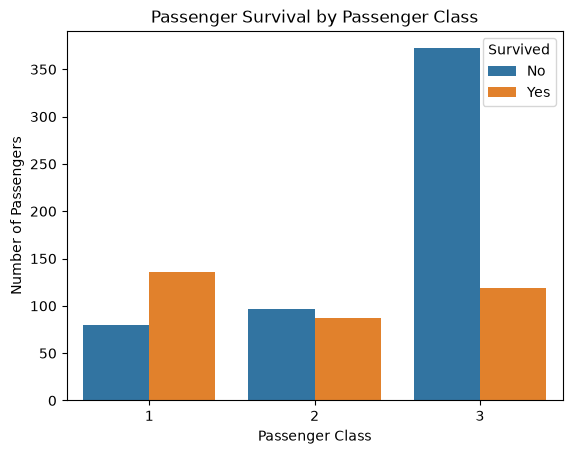

In [5]:

sns.countplot(data=df, x="Pclass", hue="Survived")
plt.title("Passenger Survival by Passenger Class")
plt.xlabel("Passenger Class")
plt.ylabel("Number of Passengers")
plt.legend(title="Survived", labels=["No", "Yes"])
plt.show()


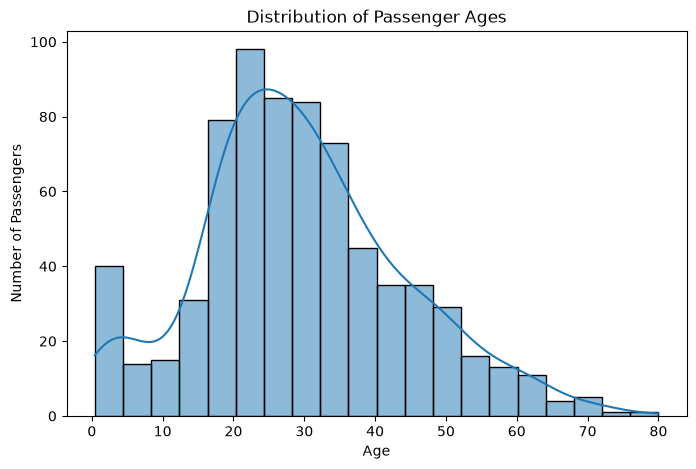

In [6]:

plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Age", bins=20, kde=True)

plt.title("Distribution of Passenger Ages")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()


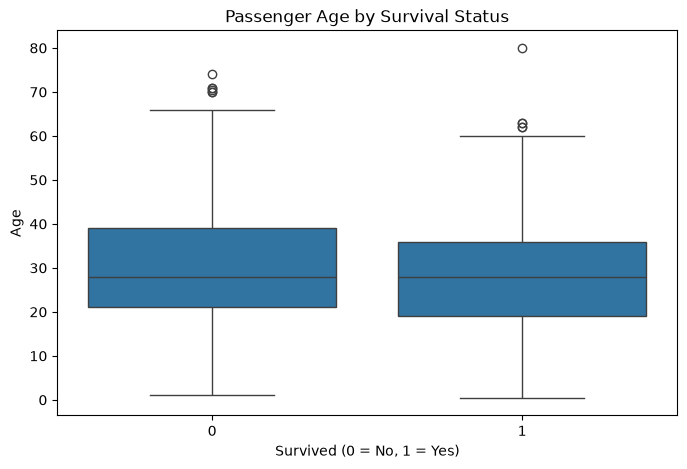

In [7]:

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Survived", y="Age")

plt.title("Passenger Age by Survival Status")
plt.xlabel("Survived (0 = No, 1 = Yes)")
plt.ylabel("Age")

plt.show()


Survival rate by sex (%):
Sex
female    74.20
male      18.89
Name: Survived, dtype: float64


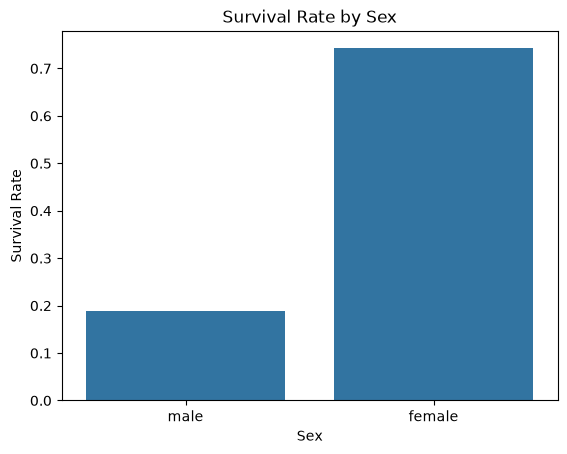

In [8]:

survival_by_sex = df.groupby("Sex")["Survived"].mean() * 100

print("Survival rate by sex (%):")
print(survival_by_sex.round(2))

sns.barplot(data=df, x="Sex", y="Survived", errorbar=None)

plt.title("Survival Rate by Sex")
plt.xlabel("Sex")
plt.ylabel("Survival Rate")
plt.show()


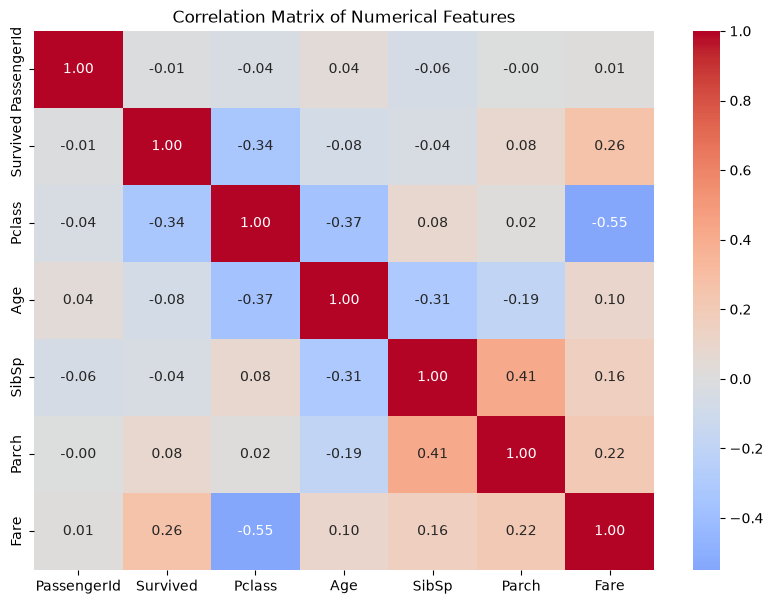

In [9]:

numeric_df = df.select_dtypes(include="number")

correlation_matrix = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()


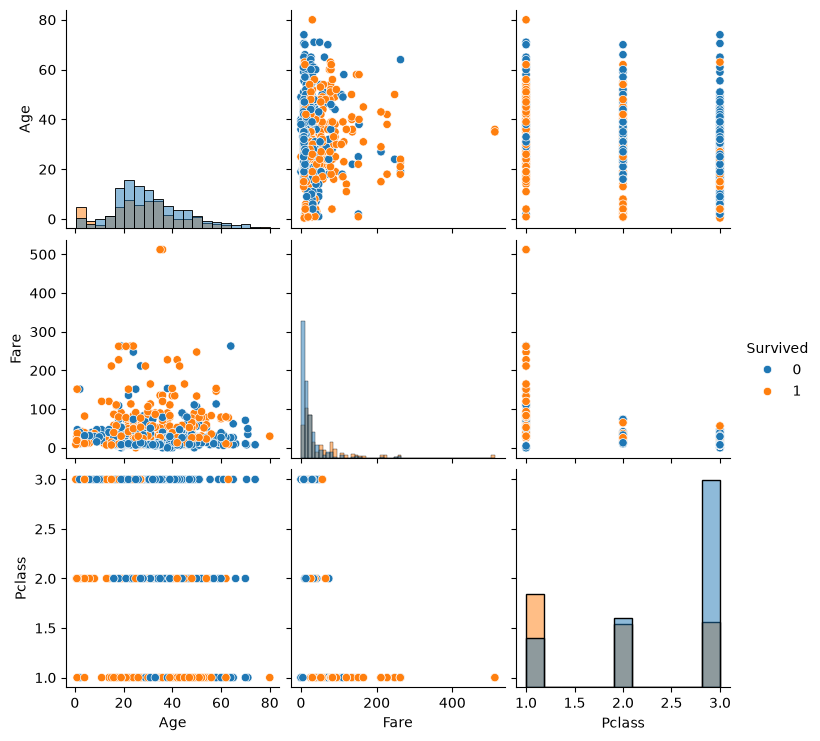

In [10]:

pair_data = df[["Survived", "Age", "Fare", "Pclass"]].dropna()

sns.pairplot(
    pair_data,
    hue="Survived",
    diag_kind="hist"
)

plt.show()


In [11]:
#data preprocessing
# Select the input features
features = ["Pclass", "Sex", "Age", "SibSp",
            "Parch", "Fare", "Embarked"]

X = df[features]
y = df["Survived"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())


Features shape: (891, 7)
Target shape: (891,)


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,3,male,22.0,1,0,7.2500,S
1,1,female,38.0,1,0,71.2833,C
2,3,female,26.0,0,0,7.9250,S
3,1,female,35.0,1,0,53.1000,S
4,3,male,35.0,0,0,8.0500,S


0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [12]:
    
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training targets:", y_train.shape)
print("Testing targets:", y_test.shape)


Training features: (712, 7)
Testing features: (179, 7)
Training targets: (712,)
Testing targets: (179,)


In [13]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)


Processed training shape: (712, 10)
Processed testing shape: (179, 10)


In [14]:

from sklearn.linear_model import LogisticRegression

# Create the Logistic Regression model
model = LogisticRegression(max_iter=1000)

# Train using the preprocessed training data
model.fit(X_train_processed, y_train)

print("Logistic Regression model trained successfully!")


Logistic Regression model trained successfully!


In [15]:

# Predict survival classes
y_pred = model.predict(X_test_processed)

# Predict probabilities of survival
y_prob = model.predict_proba(X_test_processed)[:, 1]

print("First 10 actual outcomes:")
print(y_test.iloc[:10].to_list())

print("\nFirst 10 predicted outcomes:")
print(y_pred[:10])

print("\nFirst 10 survival probabilities:")
print(y_prob[:10].round(3))


First 10 actual outcomes:
[0, 0, 1, 0, 1, 1, 1, 0, 0, 0]

First 10 predicted outcomes:
[0 0 0 0 1 0 1 0 0 0]

First 10 survival probabilities:
[0.068 0.048 0.155 0.036 0.672 0.443 0.753 0.328 0.347 0.161]


In [16]:

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print(f"Accuracy : {accuracy:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")
print(f"ROC-AUC  : {roc_auc:.3f}")


Accuracy : 0.804
Precision: 0.793
Recall   : 0.667
F1-score : 0.724
ROC-AUC  : 0.844


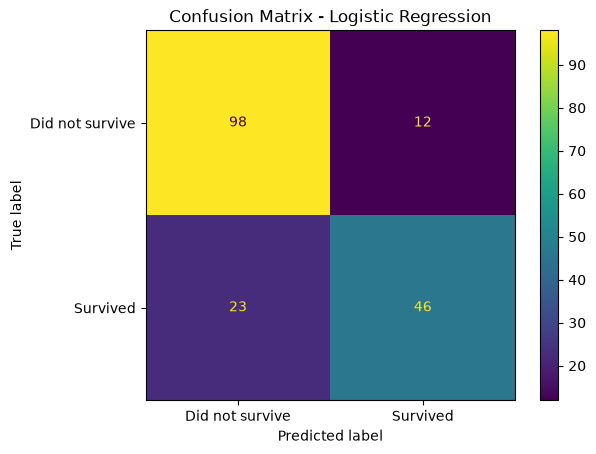

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did not survive", "Survived"]
)

display.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()


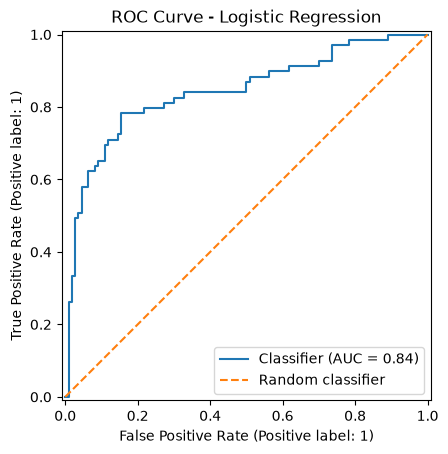

In [18]:

from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(y_test, y_prob)

plt.title("ROC Curve - Logistic Regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.legend()
plt.show()


In [19]:

print("Number of columns in X_train:", len(X_train.columns))
print("Number of model coefficients:", len(model.coef_[0]))

print("\nTraining columns:")
print(X_train.columns.tolist())

print("\nModel coefficient shape:")
print(model.coef_.shape)


Number of columns in X_train: 7
Number of model coefficients: 10

Training columns:
['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']

Model coefficient shape:
(1, 10)


In [20]:

feature_names = preprocessor.get_feature_names_out()

print("Number of transformed features:", len(feature_names))
print("Feature names:")
print(feature_names)


Number of transformed features: 10
Feature names:
['numeric__Pclass' 'numeric__Age' 'numeric__SibSp' 'numeric__Parch'
 'numeric__Fare' 'categorical__Sex_female' 'categorical__Sex_male'
 'categorical__Embarked_C' 'categorical__Embarked_Q'
 'categorical__Embarked_S']


                   Feature  Coefficient
6    categorical__Sex_male    -1.320718
0          numeric__Pclass    -0.921972
1             numeric__Age    -0.502815
9  categorical__Embarked_S    -0.358305
2           numeric__SibSp    -0.260607
3           numeric__Parch    -0.066424
7  categorical__Embarked_C     0.032247
4            numeric__Fare     0.100269
8  categorical__Embarked_Q     0.304784
5  categorical__Sex_female     1.299444


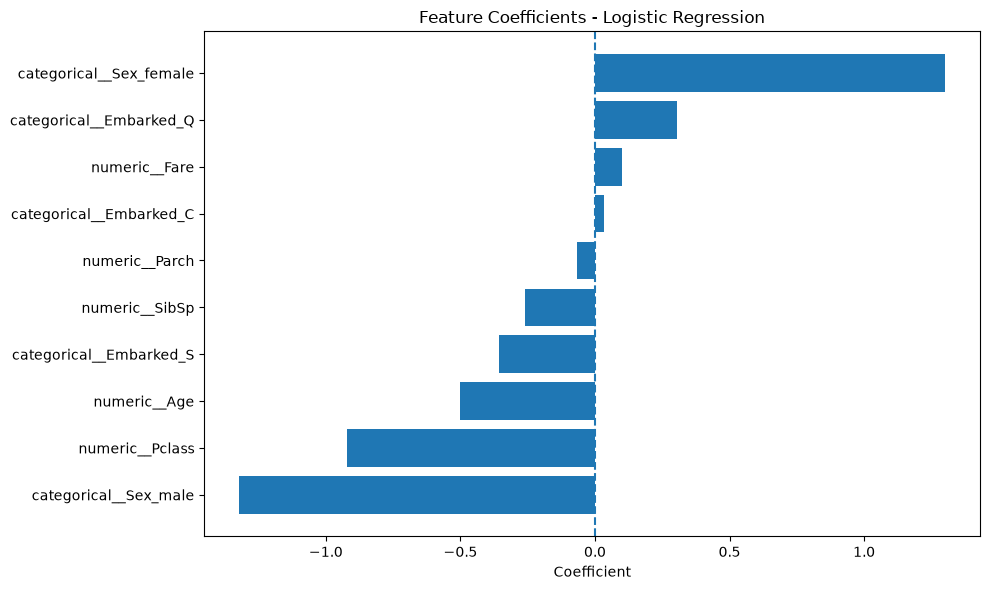

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

coefficients = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": model.coef_[0]
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    ascending=True
)

print(coefficients)

plt.figure(figsize=(10, 6))
plt.barh(
    coefficients["Feature"],
    coefficients["Coefficient"]
)
plt.axvline(x=0, linestyle="--")
plt.title("Feature Coefficients - Logistic Regression")
plt.xlabel("Coefficient")
plt.tight_layout()
plt.show()


In [22]:
%pip install streamlit joblib

Note: you may need to restart the kernel to use updated packages.


In [23]:

import joblib

joblib.dump(model, "titanic_pipeline.pkl")

print("Pipeline saved successfully!")


Pipeline saved successfully!


In [24]:


import joblib

joblib.dump(Pipeline, "titanic_pipeline.pkl")

print("Complete pipeline saved successfully!")
print(Pipeline)



Complete pipeline saved successfully!
<class 'sklearn.pipeline.Pipeline'>


In [25]:

import joblib
from sklearn.pipeline import Pipeline as SklearnPipeline

# Combine the fitted preprocessor and trained classifier
full_pipeline = SklearnPipeline([
    ("preprocessor", preprocessor),
    ("classifier", model)
])

# Save the complete pipeline
joblib.dump(full_pipeline, "titanic_pipeline.pkl")

print("Complete pipeline saved successfully!")
print(full_pipeline)


Complete pipeline saved successfully!
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Pclass', 'Age', 'SibSp',
                                                   'Parch', 'Fare']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                              

In [26]:

saved_pipeline = joblib.load("titanic_pipeline.pkl")

print("Pipeline steps:", list(saved_pipeline.named_steps.keys()))

# Test with one sample passenger
import pandas as pd

sample_passenger = pd.DataFrame([{
    "Pclass": 3,
    "Sex": "male",
    "Age": 22,
    "SibSp": 1,
    "Parch": 0,
    "Fare": 7.25,
    "Embarked": "S"
}])

print("Prediction:", saved_pipeline.predict(sample_passenger)[0])
print(
    "Survival probability:",
    saved_pipeline.predict_proba(sample_passenger)[0][1]
)


Pipeline steps: ['preprocessor', 'classifier']
Prediction: 0
Survival probability: 0.0886348011642858


In [28]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Transform the test data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# Predict using the trained Logistic Regression model
y_pred = model.predict(X_test_processed)

# Evaluate the model
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8044692737430168

Classification Report:
              precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179


Confusion Matrix:
[[98 12]
 [23 46]]


In [31]:
import os

print("Current folder:", os.getcwd())
print("Files in folder:", os.listdir())

Current folder: C:\Users\revel\ML-Practice
Files in folder: ['.ipynb_checkpoints', '.venv', 'app.py', 'ML-Basics.ipynb', 'titanic.csv', 'TitanicSurvivalPredictionmodel.ipynb', 'titanic_pipeline.pkl']
